<a href="https://colab.research.google.com/github/LiaIssakov/Portfolio_2025/blob/main/tSNE_explosion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Visualizing tSNE iterations

We look at how tSNE evelves the embedding



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from keras.datasets import mnist, fashion_mnist
from sklearn.manifold import TSNE # !

# just technicalities
plt.rcParams["figure.figsize"] = (15,15)

from ipywidgets import *
import ipywidgets as widgets

In [ ]:
(x_train, y_train), _ = mnist.load_data()
NUM_VECTORS = 2500 #
x_train = x_train[:NUM_VECTORS]/255.
y_train = y_train[:NUM_VECTORS]

FLAT_SHAPE = (NUM_VECTORS, 28*28)

In [ ]:
(x_train, y_train), _ = mnist.load_data()
NUM_VECTORS = 1000 #
x_train = x_train[:NUM_VECTORS]/255.
y_train = y_train[:NUM_VECTORS]

FLAT_SHAPE = (NUM_VECTORS, 28*28)

In [ ]:
num_iters = 1000 # PARAM
perplexity = 20 # PARAM
my_random_state = 1236 # PARAM
dim_red = TSNE(n_components = 2, max_iter = num_iters,
               perplexity = perplexity, random_state = my_random_state) # how does the perplexity param change the results?

In [ ]:
dim_red.fit(x_train.reshape(FLAT_SHAPE))
x_reduced = dim_red.embedding_ # alternative: tip_transform does fit then transform, and returns

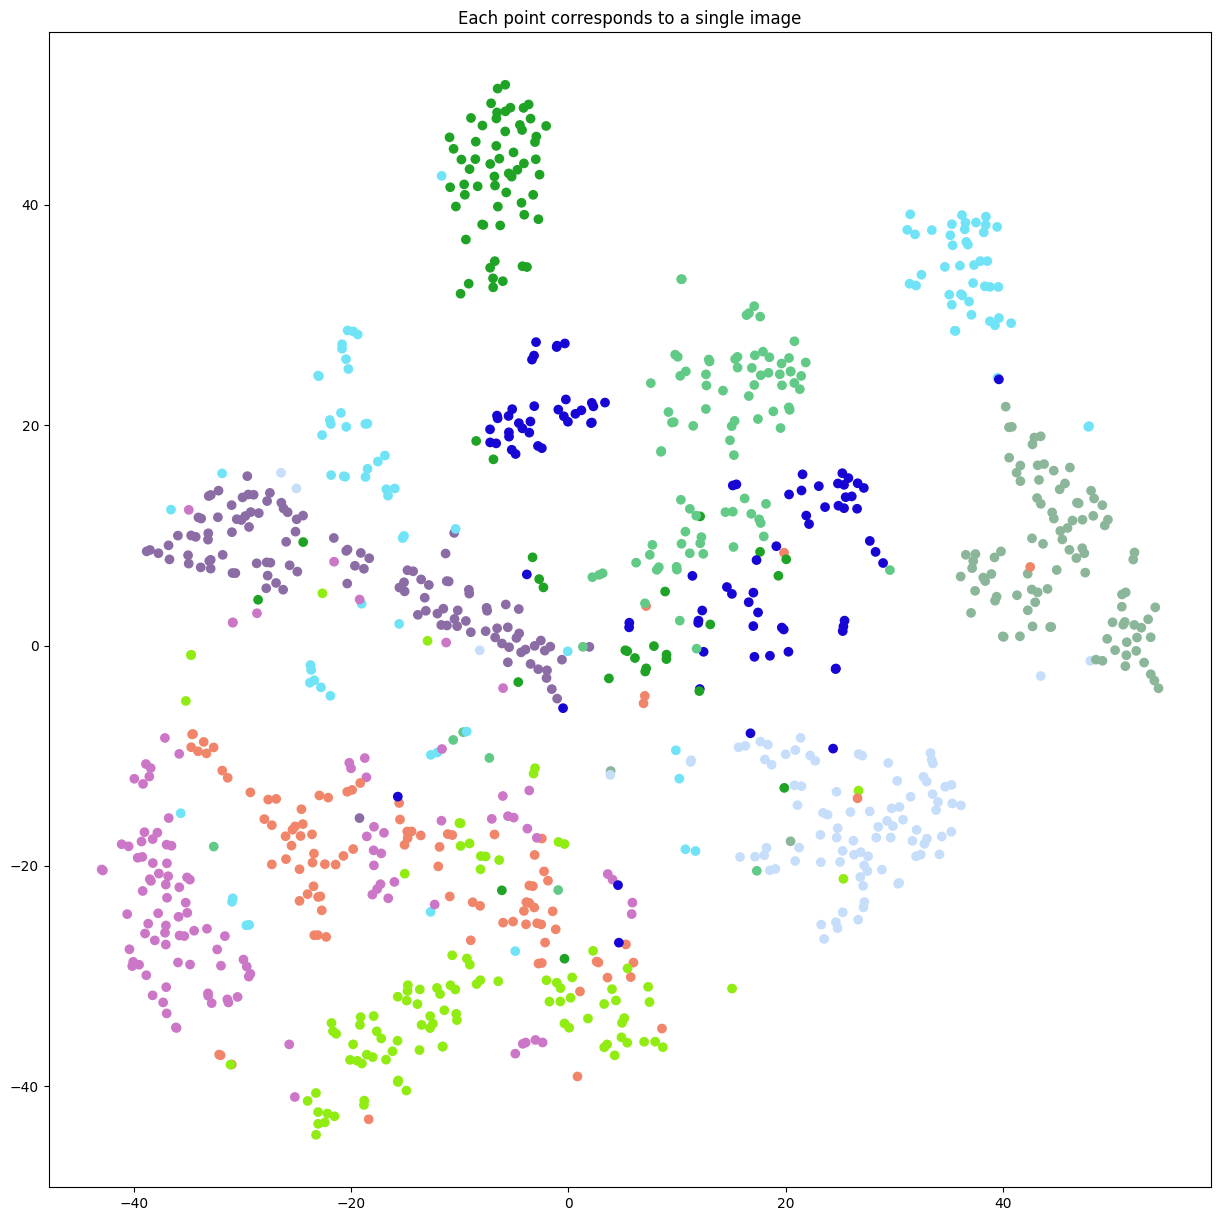

In [ ]:
np.random.seed(0)
plt.figure(figsize = (15,15))
colors = np.random.rand(NUM_VECTORS, 3)[y_train]
plt.scatter(*x_reduced.T, c = colors)
plt.title('Each point corresponds to a single image')

plt.savefig(f'res_with_perplexity_{perplexity}.png')

# How tSNE iteratively improves the result

In [ ]:
def evolve_tsne(X, embs_out, info_out, iters, each_iter = 1):
  '''
  Just a technicality to see tSNE output for different results.
  You can safely disregard the implementation.

  Semi-interesting trick: if the below function returned the result,
  and we stopped the cell's execution -- we'd lose the result.
  But as written we can stop and still get the results so far!
  '''
  embs_out.clear()
  info_out.clear()

  for i in range(250, iters+1, each_iter):
    dim_red = TSNE(n_components=2, n_iter=i,
               perplexity=perplexity, init='pca', random_state=my_random_state)
    dim_red.fit(X)
    embs_out.append(dim_red.embedding_)
    info_out.append((i, dim_red.kl_divergence_))

import warnings
warnings.filterwarnings("ignore")

embs = []
info = []
evolve_tsne(x_train.reshape(FLAT_SHAPE), embs_out=embs, info_out=info,
            iters=500, each_iter=5)

In [ ]:
embs = np.asarray(embs)

interactive(children=(IntSlider(value=0, description='t', max=50), Output()), layout=Layout(height='1000px', w…

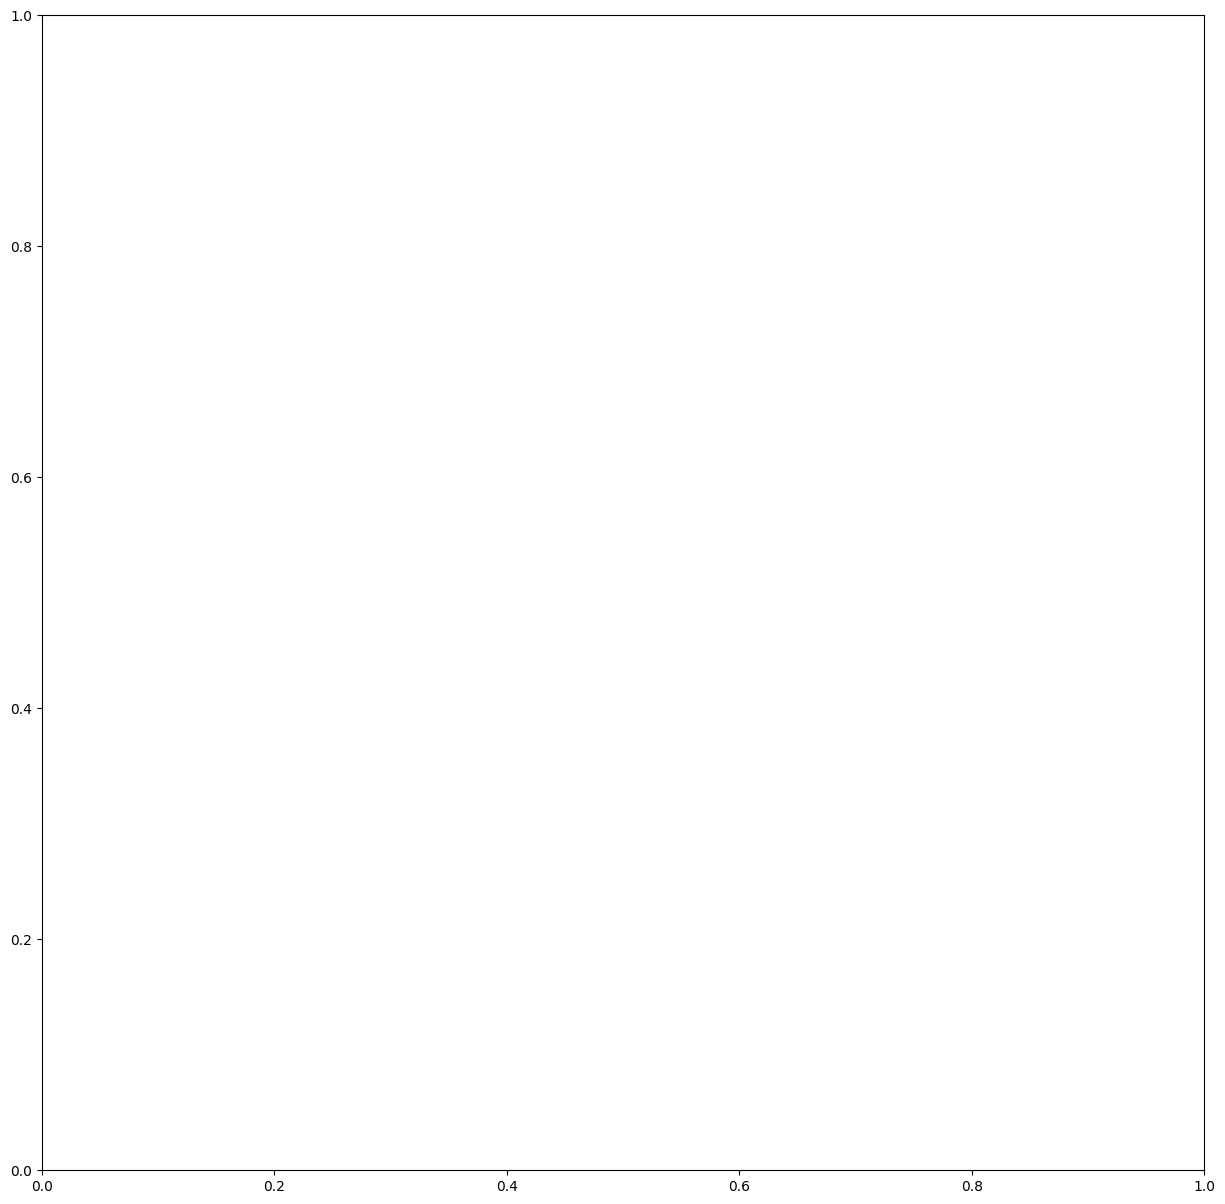

In [ ]:
# The below allows us to plot the i-th iteration of tSNE
# Disregard the implementation

#fig, ax = plt.subplots(1,1)
ax = plt.gca()

def plot_tsne(t):
  plt.sca(ax)
  plt.cla()
  emb = embs[t]
  iter, kl = info[t]
  plt.scatter(emb.T[0], emb.T[1], c = colors)
  plt.title(f'iter={iter} with loss={kl}')

  # Advanced tip: [..., 0] is eq. to [:,  0], [:, :, 0], [:, :, :, 0] etc --
  # -- quite useful if you don't know the number of dimensions of the array
  plt.xlim(embs[..., 0].min(), embs[..., 0].max())
  plt.ylim(embs[..., 1].min(), embs[..., 1].max())

  plt.show()


sl = lambda x : widgets.IntSlider(value=x, min=0, max=len(embs)-1, step=1)
interactive_plot = interactive(plot_tsne, t = sl(0), grid = False)
interactive_plot.layout.height = '1000px'
interactive_plot.layout.width = '1000px'
interactive_plot
#HBox([interactive_plot])
###